# UJI SENSITIVITAS SPASIAL P90-D3 — Tmax vs UTCImax Pulau Jawa, 1996–2025
### Adaptasi gaya jurnal: angka pada plot, grafik sensitivitas, dan peta SMOOTH

**Input:** cache HWF enam skenario Tmax Jawa dengan fingerprint konsisten dan NetCDF metrik UTCImax Jawa dari hasil pengolahan sebelumnya. **Tidak mendeteksi ulang heatwave.**

**Statistik pada grid asli:** persentase perubahan HWF regional berbobot cos(latitude), Spearman ρ (spasial), Pearson r, overlap hotspot Jaccard. Interpolasi hanya dilakukan saat menggambar peta kontinuitas spasial, tidak pada perhitungan maupun kelas hotspot.

**Cakupan:** Banten, DKI Jakarta, Jawa Barat, Jawa Tengah, DI Yogyakarta, Jawa Timur. **Benchmark:** P90-D3. **Skenario:** P90/P95 × D3/D4/D5.

**Path utama:** `D:\Daps\Data`; opsi override di Sel 1 bila perlu. Notebook menolak cache campur fingerprint dan tidak mengasumsikan grid Tmax = UTCI.


## Persyaratan dan jalur input
Paket minimal `numpy pandas xarray scipy matplotlib shapely geopandas openpyxl netCDF4`. Untuk batas Natural Earth 10m dan peta geografis: `cartopy` (atau isi `SHAPEFILE_ADMIN1` dengan SHP lokal Jawa).

```bash
pip install numpy pandas xarray scipy matplotlib cartopy shapely geopandas pyogrio netCDF4 openpyxl
```

**Urutan:** Sel 1 mendeteksi lokasi hasil Tmax Jawa di `D:\Daps\Data` tanpa mencari CSV annual; Sel 2 memilih enam cache HWF dengan fingerprint yang sama; Sel 3–4 membaca dan melakukan QC metrik Tmax serta UTCI; sel berikutnya menghitung statistik dan menggambar grafik.


In [1]:
# SEL 1 — KONFIGURASI JAWA (1996–2025) | PATH D:\Daps\Data
from pathlib import Path
import os, json, re, warnings, unicodedata
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import colors, patheffects
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, MultipleLocator
from scipy.stats import spearmanr, pearsonr
from IPython.display import display, Markdown

warnings.filterwarnings('ignore', message='Mean of empty slice')

# PATH ASLI PENGGUNA: D:\Daps\Data; tidak memakai path dari komputer referensi.
DATA_BASE = Path(os.environ.get('DAPS_DATA_BASE', r'D:\Daps\Data'))
UTCI_ROOT = DATA_BASE / 'UTCI' / 'Hasil_UTCI_Jawa_1996_2025'
UTCI_RUN = UTCI_ROOT / 'UTCI_Jawa_Heatwave_Journal_SMOOTH'
UTCI_METRICS_FILE = (UTCI_RUN / 'data' /
                     'UTCI_Jawa_Heatwave_Metrics_AllScenarios_1996_2025.nc')

# Hanya isi jika pencarian otomatis tidak menemukan folder dari notebook Tmax Jawa.
# TMAX_ROOT_OVERRIDE = folder OUTPUT_DIR notebook Tmax (mempunyai cache/ & results/)
# TMAX_RAW_DIR_OVERRIDE = folder TMAX_DIR tempat NetCDF suhu asli disimpan
TMAX_ROOT_OVERRIDE = None
TMAX_RAW_DIR_OVERRIDE = None
TMAX_COORDS_NPZ = None  # Opsional: .npz berisi lat, lon dalam urutan cache
TMAX_CACHE_TAG_OVERRIDE = None  # Opsional: 'jawa_1996_2025_<fingerprint>'

START_YEAR, END_YEAR = 1996, 2025
YEARS = np.arange(START_YEAR, END_YEAR + 1)
SCENARIOS = ['P90_D3', 'P90_D4', 'P90_D5', 'P95_D3', 'P95_D4', 'P95_D5']
BENCHMARK = 'P90_D3'
OTHER_SCENARIOS = [s for s in SCENARIOS if s != BENCHMARK]
STRICTEST_SCENARIO_ON_TOP = True
HOTSPOT_TOP_FRACTION = .20
MAP_EXTENT = [104.5, 116.5, -9.3, -4.9]
STRICT_QC = True
FIG_DPI = 350
SAVE_PDF = True
SHOW_INLINE = True
DISPLAY_RENDER = 'smooth' # Interpolasi TAMPILAN saja, tidak untuk statistik
DISPLAY_NX, DISPLAY_NY = 650, 260
STRICT_SMOOTH_MAP = True
MAKE_OPTIONAL_HOTSPOT_FIGURE = True
# Pakai SHP Jawa bila ingin memakai batas administrasi lokal (CRS EPSG:4326).
# Jika None, otomatis menggunakan Natural Earth Admin-1 10m via Cartopy.
SHAPEFILE_ADMIN1 = None


def _valid_jawa_cache(root):
    cache = root / 'cache'
    if not cache.is_dir():
        return False
    for meta_fp in cache.glob('daily_metadata_jawa_1996_2025_*.json'):
        tag = meta_fp.stem.replace('daily_metadata_', '', 1)
        try:
            meta = json.loads(meta_fp.read_text(encoding='utf-8'))
            if meta.get('region', '').strip().lower() != 'jawa':
                continue
            if list(meta.get('period', [])) != [START_YEAR, END_YEAR]:
                continue
            if not all((cache / f'metrics_{s}_W15_{tag}.npz').is_file() for s in SCENARIOS):
                continue
            if not (cache / f'calendar_thresholds_P90_P95_W15_{tag}.npz').is_file():
                continue
            return True
        except (OSError, ValueError, TypeError, KeyError):
            continue
    return False


def find_tmax_root(base):
    if TMAX_ROOT_OVERRIDE is not None:
        p = Path(TMAX_ROOT_OVERRIDE)
        if not _valid_jawa_cache(p):
            raise FileNotFoundError('TMAX_ROOT_OVERRIDE salah / cache enam skenario tidak lengkap: ' + str(p) +
                                    '\nMasukkan nilai OUTPUT_DIR pada notebook Tmax Jawa.')
        return p
    roots = [base / 'Hasil_Tmax', base / 'TMAX', base / 'Tmax', base / 'T2M Max', base]
    subdirs = ('HEATWAVE_JAWA_JOURNAL_OUTPUT', 'Heatwave_Jawa_Journal_Combined',
               'TMAX_Heatwave_Jawa', 'Heatwave_Jawa')
    candidates = set(roots)
    candidates.update(r / sub for r in roots for sub in subdirs)
    # Scan HANYA nama folder/cache dan JSON kecil, tidak membaca file NetCDF besar.
    if base.is_dir():
        depth0 = len(base.parts)
        for current, folders, names in os.walk(base):
            here = Path(current)
            if here.name.lower() == 'cache' and any(
                n.startswith('daily_metadata_jawa_1996_2025_') and n.endswith('.json')
                for n in names):
                candidates.add(here.parent)
            if len(here.parts) - depth0 >= 7:
                folders[:] = []
            else:
                folders[:] = [f for f in folders if f.lower() not in
                    {'raw', '1996-2025', 'plots', 'figures', 'maps_netcdf',
                     'site-packages', '.git', '__pycache__'}]
    valid = sorted({p.resolve() for p in candidates if _valid_jawa_cache(p)})
    if len(valid) == 1:
        print('✓ Folder output Tmax ditemukan:', valid[0]); return valid[0]
    if len(valid) > 1:
        raise RuntimeError('Ada beberapa OUTPUT Tmax Jawa valid. Isi TMAX_ROOT_OVERRIDE secara eksplisit:\n - '
                           + '\n - '.join(map(str, valid)))
    raise FileNotFoundError('Output Tmax Jawa lengkap tidak ditemukan di ' + str(base) +
         '\nBuka notebook Tmax yang SUDAH BERHASIL, salin nilai OUTPUT_DIR, isi TMAX_ROOT_OVERRIDE.\n'
         'Diperlukan cache metrics_{P90/P95}_{D3/D4/D5}_W15_jawa_1996_2025_<fingerprint>.npz.')


def _has_nc(p):
    return p.is_dir() and any(p.glob('*.nc'))


def find_tmax_raw(base, results):
    if TMAX_COORDS_NPZ is not None:
        p = Path(TMAX_COORDS_NPZ)
        if not p.is_file():
            raise FileNotFoundError('Koordinat Tmax (.npz) tidak ditemukan: '+str(p))
        return None
    if TMAX_RAW_DIR_OVERRIDE is not None:
        p = Path(TMAX_RAW_DIR_OVERRIDE)
        if not _has_nc(p):
            raise FileNotFoundError('Folder TMAX_RAW_DIR_OVERRIDE tidak berisi *.nc: '+str(p))
        return p
    qc = results / 'QC_input_files.csv'
    if qc.is_file():
        try:
            frame = pd.read_csv(qc)
            if 'path' in frame.columns:
                valid = list(dict.fromkeys(Path(str(v)).parent for v in frame['path'].dropna()))
                valid = [p for p in valid if _has_nc(p)]
                if len(valid) == 1:
                    print('✓ Folder mentah Tmax dari QC:', valid[0]); return valid[0]
        except (OSError, ValueError, TypeError) as exc:
            print('Info: QC_input_files.csv tidak bisa dipakai:', exc)
    candidates = [base/'T2M Max', base/'TMax', base/'TMAX'/'1996-2025',
                  base/'Tmax'/'1996-2025', base/'TMAX', base/'Tmax',
                  base/'Hasil_Tmax'/'1996-2025']
    found = sorted({p.resolve() for p in candidates if _has_nc(p)})
    if len(found) == 1:
        return found[0]
    if len(found) > 1:
        raise RuntimeError('Ditemukan beberapa folder NetCDF Tmax; isi TMAX_RAW_DIR_OVERRIDE:\n - '
                           + '\n - '.join(map(str, found)))
    raise FileNotFoundError('NetCDF mentah Tmax tidak ditemukan otomatis. Salin TMAX_DIR dari '
                            'notebook Tmax Jawa ke TMAX_RAW_DIR_OVERRIDE.')


TMAX_ROOT = find_tmax_root(DATA_BASE)
TMAX_CACHE = TMAX_ROOT / 'cache'
TMAX_RESULTS = TMAX_ROOT / 'results'
TMAX_RAW_DIR = find_tmax_raw(DATA_BASE, TMAX_RESULTS)
OUTPUT_DIR = UTCI_ROOT / 'TMAX_vs_UTCI_SENSITIVITAS_JAWA_P90D3_1996_2025'
PLOT_DIR = OUTPUT_DIR / 'figures'
TABLE_DIR = OUTPUT_DIR / 'tables'
MAP_DIR = OUTPUT_DIR / 'maps_netcdf'
for _folder in (OUTPUT_DIR, PLOT_DIR, TABLE_DIR, MAP_DIR):
    _folder.mkdir(parents=True, exist_ok=True)

mpl.rcParams.update({
    'font.family': 'serif', 'font.serif': ['DejaVu Serif'],
    'font.size': 9, 'axes.titlesize': 10, 'axes.labelsize': 9,
    'axes.edgecolor': '#303845', 'axes.linewidth': .8,
    'xtick.direction': 'out', 'ytick.direction': 'out',
    'xtick.major.size': 3, 'ytick.major.size': 3,
    'xtick.color': '#445064', 'ytick.color': '#445064',
    'grid.linewidth': .4, 'savefig.facecolor': 'white',
    'figure.facecolor': 'white', 'pdf.fonttype': 42, 'ps.fonttype': 42,
})
PALETTE = {'Tmax': '#bc5c38', 'UTCImax': '#246e88'}
print('Wilayah    : enam provinsi Jawa | Benchmark:', BENCHMARK)
print('Periode    :', START_YEAR, '–', END_YEAR)
print('Tmax output:', TMAX_ROOT)
print('Tmax mentah:', TMAX_RAW_DIR or TMAX_COORDS_NPZ)
print('UTCI       :', UTCI_METRICS_FILE)
print('Output baru:', OUTPUT_DIR)


✓ Folder output Tmax ditemukan: D:\Daps\Data\TMAX lagi\HEATWAVE_JOURNAL_OUTPUT
✓ Folder mentah Tmax dari QC: D:\Daps\Data\tm2m max
Wilayah    : enam provinsi Jawa | Benchmark: P90_D3
Periode    : 1996 – 2025
Tmax output: D:\Daps\Data\TMAX lagi\HEATWAVE_JOURNAL_OUTPUT
Tmax mentah: D:\Daps\Data\tm2m max
UTCI       : D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\UTCI_Jawa_Heatwave_Journal_SMOOTH\data\UTCI_Jawa_Heatwave_Metrics_AllScenarios_1996_2025.nc
Output baru: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\TMAX_vs_UTCI_SENSITIVITAS_JAWA_P90D3_1996_2025


## 1 — Validasi data Jawa dan enam skenario
P90-D3 digunakan sebagai benchmark; semua skenario dibandingkan terhadapnya. Metrik HWF diperoleh langsung dari cache Tmax asli (`metrics_...W15_jawa_...npz`) dan NetCDF UTCI asli (`UTCI_Jawa_Heatwave_Metrics_AllScenarios_1996_2025.nc`). Tmax dan UTCI **boleh mempunyai grid native berbeda**: perhitungan dilakukan terpisah pada masing-masing grid.


In [2]:
# SEL 2 — PILIH SATU FINGERPRINT CACHE TMAX YANG LENGKAP & PERIKSA INPUT
import re

cache_groups = {}
for p in sorted(TMAX_CACHE.glob('daily_metadata_jawa_1996_2025_*.json')):
    tag = p.stem.replace('daily_metadata_', '', 1)
    try:
        meta = json.loads(p.read_text(encoding='utf-8'))
    except (OSError, ValueError):
        continue
    if str(meta.get('region', '')).lower() != 'jawa' or list(meta.get('period', [])) != [1996,2025]:
        continue
    files = {s: TMAX_CACHE / f'metrics_{s}_W15_{tag}.npz' for s in SCENARIOS}
    threshold = TMAX_CACHE / f'calendar_thresholds_P90_P95_W15_{tag}.npz'
    if all(f.is_file() for f in files.values()) and threshold.is_file():
        cache_groups[tag] = files
if not cache_groups:
    raise FileNotFoundError('Tidak ditemukan kelompok cache lengkap Tmax Jawa (P90/P95 × D3/D4/D5) '
                            'di: '+str(TMAX_CACHE))
if TMAX_CACHE_TAG_OVERRIDE is not None:
    if TMAX_CACHE_TAG_OVERRIDE not in cache_groups:
        raise ValueError('TMAX_CACHE_TAG_OVERRIDE bukan tag lengkap. Pilihan: '+str(list(cache_groups)))
    TMAX_CACHE_TAG = TMAX_CACHE_TAG_OVERRIDE
elif len(cache_groups) == 1:
    TMAX_CACHE_TAG = next(iter(cache_groups))
else:
    raise RuntimeError('Terdapat lebih dari satu fingerprint Tmax Jawa, pilih TMAX_CACHE_TAG_OVERRIDE:\n - '
                       + '\n - '.join(cache_groups))
inputs = cache_groups[TMAX_CACHE_TAG]
raw_candidates = sorted(TMAX_RAW_DIR.glob('*.nc')) if TMAX_RAW_DIR is not None else []
if TMAX_COORDS_NPZ is None and not raw_candidates:
    raise FileNotFoundError('Tidak ada NetCDF Tmax dalam '+str(TMAX_RAW_DIR)+
                            '; isi TMAX_RAW_DIR_OVERRIDE atau TMAX_COORDS_NPZ.')
if not UTCI_METRICS_FILE.is_file():
    raise FileNotFoundError('File hasil analisis UTCI Jawa belum ditemukan:\n'+str(UTCI_METRICS_FILE)+
                            '\nPastikan notebook Step 5 UTCI Jawa telah diselesaikan.')
print('✓ Cache Tmax Jawa dipakai (fingerprint konsisten):', TMAX_CACHE_TAG)
for s, f in inputs.items():
    print(' TMAX',s,'→',f.name)
print('✓ File UTCI Jawa:', UTCI_METRICS_FILE.name)


✓ Cache Tmax Jawa dipakai (fingerprint konsisten): jawa_1996_2025_12a9a5da2da0
 TMAX P90_D3 → metrics_P90_D3_W15_jawa_1996_2025_12a9a5da2da0.npz
 TMAX P90_D4 → metrics_P90_D4_W15_jawa_1996_2025_12a9a5da2da0.npz
 TMAX P90_D5 → metrics_P90_D5_W15_jawa_1996_2025_12a9a5da2da0.npz
 TMAX P95_D3 → metrics_P95_D3_W15_jawa_1996_2025_12a9a5da2da0.npz
 TMAX P95_D4 → metrics_P95_D4_W15_jawa_1996_2025_12a9a5da2da0.npz
 TMAX P95_D5 → metrics_P95_D5_W15_jawa_1996_2025_12a9a5da2da0.npz
✓ File UTCI Jawa: UTCI_Jawa_Heatwave_Metrics_AllScenarios_1996_2025.nc


In [3]:
# SEL 3 — FUNGSI PEMBACAAN / QC

def normalize_coords(latitude, longitude):
    latitude = np.asarray(latitude, dtype=float)
    longitude = np.asarray(longitude, dtype=float)
    longitude = np.where(longitude > 180, ((longitude + 180) % 360) - 180, longitude)
    if latitude.ndim != 1 or longitude.ndim != 1:
        raise ValueError('Latitude dan longitude harus satu dimensi.')
    return latitude, longitude


def load_tmax_geocoords(shape2d):
    if TMAX_COORDS_NPZ is not None:
        with np.load(TMAX_COORDS_NPZ) as z:
            lat = np.asarray(z['lat'], dtype=float)
            lon = np.asarray(z['lon'], dtype=float)
        # npz opsi ini memang sudah dalam urutan cache.
    else:
        ds_coord = xr.open_dataset(raw_candidates[0], decode_times=False)
        try:
            lat_name = next((c for c in ['latitude', 'lat', 'Latitude', 'LAT'] if c in ds_coord), None)
            lon_name = next((c for c in ['longitude', 'lon', 'Longitude', 'LON'] if c in ds_coord), None)
            if not lat_name or not lon_name:
                raise KeyError('Koordinat Tmax latitude/longitude tidak ditemukan pada file mentah.')
            lat = ds_coord[lat_name].values
            lon = ds_coord[lon_name].values
        finally:
            ds_coord.close()
        lat, lon = normalize_coords(lat, lon)
        # Cache Tmax diproses dengan sort ascending KEDUA koordinatnya.
        lat = lat[np.argsort(lat)]
        lon = lon[np.argsort(lon)]
    if (len(lat), len(lon)) != shape2d:
        raise ValueError(
            f'Koordinat Tmax {len(lat)}x{len(lon)} tidak cocok dengan cache {shape2d}. '
            'Periksa referensi berkas mentah yang dipilih.'
        )
    if np.any(np.diff(lat) <= 0) or np.any(np.diff(lon) <= 0):
        raise ValueError('Urutan koordinat cache Tmax harus ascending.')
    return lat, lon


def load_tmax_hwf():
    blocks = []
    for scen in SCENARIOS:
        with np.load(inputs[scen]) as z:
            if 'HWF' not in z or 'years' not in z:
                raise KeyError(f'Cache {scen} tidak memiliki HWF/years.')
            years = np.asarray(z['years'], dtype=int)
            values = np.asarray(z['HWF'], dtype=np.float32)
        if not np.array_equal(years, YEARS):
            raise ValueError(f'Tahun pada cache {scen} tidak sesuai {START_YEAR}–{END_YEAR}.')
        if values.ndim != 3 or values.shape[0] != len(YEARS):
            raise ValueError(f'Shape HWF Tmax {scen} tidak sesuai (30, lat, lon): {values.shape}')
        if blocks and values.shape != blocks[0].shape:
            raise ValueError(f'Shape grid HWF Tmax berubah pada skenario {scen}.')
        blocks.append(values)
    cube = np.stack(blocks, axis=0)  # (scenario, year, lat, lon)
    lat, lon = load_tmax_geocoords(cube.shape[-2:])
    return cube, lat, lon


def load_utci_hwf():
    ds = xr.open_dataset(UTCI_METRICS_FILE, decode_timedelta=False)
    try:
        if 'HWF' not in ds:
            raise KeyError('Variabel HWF tidak ditemukan pada metrik UTCI.')
        da = ds['HWF']
        expected_dims = {'percentile', 'min_duration', 'year', 'latitude', 'longitude'}
        if set(da.dims) != expected_dims:
            raise ValueError(f'Dimensi UTCI tidak sesuai: {da.dims}')
        arrs = []
        for scen in SCENARIOS:
            p, d = [int(x) for x in scen.replace('P', '').split('_D')]
            arr = da.sel(percentile=p, min_duration=d).transpose('year', 'latitude', 'longitude')
            years = np.asarray(arr['year'].values, dtype=int)
            if not np.array_equal(years, YEARS):
                raise ValueError(f'Tahun UTCI {scen} tidak lengkap atau urutannya berbeda.')
            arrs.append(np.asarray(arr.values, dtype=np.float32))
        cube = np.stack(arrs, axis=0)
        lat, lon = normalize_coords(ds['latitude'].values, ds['longitude'].values)
        li, lj = np.argsort(lat), np.argsort(lon)
        cube = cube[:, :, li, :][:, :, :, lj]
        lat, lon = lat[li], lon[lj]
    finally:
        ds.close()
    if np.any(np.diff(lat) <= 0) or np.any(np.diff(lon) <= 0):
        raise ValueError('Koordinat UTCI tidak unik/ascending setelah normalisasi.')
    return cube, lat, lon


def annual_cube_to_maps(cube, name):
    # Memakai grid dengan 30 tahun lengkap untuk KEENAM skenario.
    valid = np.all(np.isfinite(cube), axis=(0, 1))
    if np.count_nonzero(valid) < 10:
        raise ValueError(f'{name}: terlalu sedikit grid dengan 30 tahun HWF lengkap.')
    if np.any(cube[:, :, valid] < 0):
        raise ValueError(f'{name}: ditemukan HWF negatif.')
    if np.any(cube[:, :, valid] > 366):
        raise ValueError(f'{name}: ditemukan HWF > 366 hari/tahun.')
    maps = np.mean(cube, axis=1, dtype=np.float64)
    maps[:, ~valid] = np.nan
    return maps, valid


def validate_nested_scenarios(maps, valid, name):
    # Ketatnya kriteria bertambah: HWF tidak boleh meningkat.
    pairs = [('P90_D3', 'P90_D4'), ('P90_D4', 'P90_D5'),
             ('P95_D3', 'P95_D4'), ('P95_D4', 'P95_D5'),
             ('P90_D3', 'P95_D3'), ('P90_D4', 'P95_D4'), ('P90_D5', 'P95_D5')]
    violations = []
    for loose, strict in pairs:
        a, b = maps[SCENARIOS.index(loose)], maps[SCENARIOS.index(strict)]
        bad = (b[valid] - a[valid]) > 1e-5
        if np.any(bad):
            violations.append(f'{loose} → {strict}: {int(bad.sum())} grid')
    if violations:
        msg = f'{name}: HWF tidak monoton! ' + '; '.join(violations)
        if STRICT_QC:
            raise ValueError(msg + '. Periksa input/output metrik atau definisi kejadian.')
        warnings.warn(msg)
    else:
        print(f'{name}: QC nested-scenarios LULUS.')
    return violations

In [4]:
# SEL 4 — LOAD DATA NYATA DARI WORKFLOW SKRIPSI
collections = {}
for indikator, loader in [('Tmax', load_tmax_hwf), ('UTCImax', load_utci_hwf)]:
    cube, lat, lon = loader()
    maps, valid = annual_cube_to_maps(cube, indikator)
    violations = validate_nested_scenarios(maps, valid, indikator)
    collections[indikator] = {
        'maps': maps, 'valid': valid, 'lat': lat, 'lon': lon,
        'years': YEARS.copy(), 'violations': violations,
    }
    print(f'{indikator:8s} | grid={maps.shape[-2:]} | valid={valid.sum()} '
          f'| HWF P90-D3 mean={np.nanmean(maps[0]):.2f} hari/tahun')
    del cube

Tmax: QC nested-scenarios LULUS.
Tmax     | grid=(15, 45) | valid=176 | HWF P90-D3 mean=13.70 hari/tahun
UTCImax: QC nested-scenarios LULUS.
UTCImax  | grid=(12, 36) | valid=176 | HWF P90-D3 mean=11.19 hari/tahun


## 2 — Statistik sensitivitas: perubahan HWF, Spearman, dan hotspot Jaccard

- **Penurunan regional (%)** = 100 × (rerata berbobot HWF P90-D3 − rerata HWF skenario) / rerata HWF P90-D3. Pembobotan berdasarkan kosinus lintang, tanpa interpolasi.
- **Spearman ρ:** kesesuaian peringkat klimatologi HWF antargrid skenario terhadap P90-D3. Dihitung dari pasangan grid valid yang sama, bukan dari nilai smoothed.
- **Jaccard:** irisan ÷ gabungan grid hotspot. Hotspot = **20% teratas** dari grid dengan HWF positif di masing-masing skenario. Nilai 1 = hotspot identik, 0 = tak beririsan.

HWF P90-D3 = 0 pada suatu grid menyebabkan **persen penurunan grid tersebut tidak terdefinisi** (NaN). Grid ini tetap masuk perhitungan rerata regional. Korelasi spasial dilaporkan secara **deskriptif**, sebab sel grid bertetangga memiliki autokorelasi spasial.

In [5]:
# SEL 5 — FUNGSI STATISTIK (KORELASI, SELISIH, HOTSPOT)

def area_mean(z, latitude, grid_mask):
    w = np.broadcast_to(np.cos(np.deg2rad(latitude))[:, None], z.shape)
    m = grid_mask & np.isfinite(z) & np.isfinite(w)
    if not np.any(m):
        return np.nan
    return float(np.sum(z[m] * w[m]) / np.sum(w[m]))


def safe_correlations(a, b, mask):
    x, y = a[mask], b[mask]
    if x.size < 3 or np.unique(x).size < 2 or np.unique(y).size < 2:
        return np.nan, np.nan
    return float(spearmanr(x, y).statistic), float(pearsonr(x, y).statistic)


def hotspot_mask(arr, mask, fraction):
    eligible = mask & np.isfinite(arr) & (arr > 0)
    hotspot = np.zeros(arr.shape, dtype=bool)
    if not np.any(eligible):
        return hotspot, np.nan
    cut = float(np.quantile(arr[eligible], 1.0 - fraction))
    hotspot[eligible] = arr[eligible] >= cut - 1e-10
    return hotspot, cut


def compute_one_indicator(name, col):
    lat, lon, valid = col['lat'], col['lon'], col['valid']
    maps = col['maps']
    base = maps[SCENARIOS.index(BENCHMARK)]
    weights_mask = valid & np.isfinite(base)
    baseline_hot, base_cut = hotspot_mask(base, weights_mask, HOTSPOT_TOP_FRACTION)
    base_regional = area_mean(base, lat, weights_mask)

    results = {}
    rows = []
    for i, scen in enumerate(SCENARIOS):
        field = maps[i]
        common = weights_mask & np.isfinite(field)
        diff = np.where(common, field - base, np.nan)
        reduction_pct = np.full(base.shape, np.nan, dtype=float)
        eligible = common & (base > 0)
        reduction_pct[eligible] = 100.0 * (base[eligible] - field[eligible]) / base[eligible]
        rho, r = safe_correlations(base, field, common)

        hot, hot_cut = hotspot_mask(field, common, HOTSPOT_TOP_FRACTION)
        # Kategori 0: bukan hotspot, 1: baseline saja, 2: skenario saja, 3: keduanya.
        classes = np.zeros(base.shape, dtype=np.int8)
        classes[baseline_hot & ~hot] = 1
        classes[~baseline_hot & hot] = 2
        classes[baseline_hot & hot] = 3
        classes[~common] = -1
        union = baseline_hot | hot
        intersection = baseline_hot & hot
        union_n = int(union.sum())
        inter_n = int(intersection.sum())
        base_n = int(baseline_hot.sum())
        alt_n = int(hot.sum())
        jaccard = inter_n / union_n if union_n else np.nan
        retention = 100 * inter_n / base_n if base_n else np.nan

        scenario_regional = area_mean(field, lat, common)
        reg_reduction = (100 * (base_regional - scenario_regional) / base_regional
                         if np.isfinite(base_regional) and base_regional > 0 else np.nan)
        results[scen] = {
            'hwf': field, 'delta': diff, 'reduction': reduction_pct,
            'hotspot': hot, 'hotspot_class': classes,
            'spearman': rho, 'pearson': r, 'jaccard': jaccard,
        }
        rows.append({
            'indicator': name, 'scenario': scen,
            'n_valid_grid': int(common.sum()),
            'n_benchmark_positive_grid': int(eligible.sum()),
            'benchmark_hwf_area_mean_days_per_year': base_regional,
            'scenario_hwf_area_mean_days_per_year': scenario_regional,
            'delta_hwf_area_mean_days_per_year': scenario_regional - base_regional,
            'reduction_regional_percent': reg_reduction,
            'median_grid_reduction_percent': float(np.median(reduction_pct[eligible])) if eligible.any() else np.nan,
            'spearman_rho': rho, 'pearson_r': r,
            'benchmark_hotspot_cutoff_days_per_year': base_cut,
            'scenario_hotspot_cutoff_days_per_year': hot_cut,
            'n_baseline_hotspot': base_n, 'n_scenario_hotspot': alt_n,
            'n_hotspot_overlap': inter_n, 'hotspot_jaccard': jaccard,
            'hotspot_retention_percent': retention,
        })
    return results, pd.DataFrame(rows)

statistics = {}
frames = []
for indicator, col in collections.items():
    result, table = compute_one_indicator(indicator, col)
    statistics[indicator] = result
    frames.append(table)
summary_df = pd.concat(frames, ignore_index=True)

display(summary_df[['indicator','scenario','spearman_rho','pearson_r',
                    'reduction_regional_percent','hotspot_jaccard',
                    'hotspot_retention_percent']].round(3))

,indicator,scenario,spearman_rho,pearson_r,reduction_regional_percent,hotspot_jaccard,hotspot_retention_percent
0,Tmax,P90_D3,1.000,1.000,0.000,1.000,100.000
1,Tmax,P90_D4,0.932,0.960,34.829,0.800,88.889
2,Tmax,P90_D5,0.890,0.925,55.345,0.762,88.889
3,Tmax,P95_D3,0.839,0.885,63.642,0.780,88.889
4,Tmax,P95_D4,0.829,0.880,78.457,0.674,80.556
5,Tmax,P95_D5,0.718,0.789,87.186,0.479,63.889
6,UTCImax,P90_D3,1.000,1.000,0.000,1.000,100.000
7,UTCImax,P90_D4,0.950,0.958,39.770,0.756,86.111
8,UTCImax,P90_D5,0.889,0.908,61.997,0.738,86.111
9,UTCImax,P95_D3,0.877,0.900,67.275,0.600,75.000


In [6]:
# TABEL UTAMA — hasil asli dihitung ulang dari file metrik
main_table = (summary_df[['indicator', 'scenario',
                          'benchmark_hwf_area_mean_days_per_year',
                          'scenario_hwf_area_mean_days_per_year',
                          'reduction_regional_percent', 'spearman_rho',
                          'hotspot_jaccard']]
              .rename(columns={
                  'indicator':'Indikator',
                  'scenario':'Skenario',
                  'benchmark_hwf_area_mean_days_per_year':'HWF P90-D3 (hari/tahun)',
                  'scenario_hwf_area_mean_days_per_year':'HWF skenario (hari/tahun)',
                  'reduction_regional_percent':'Penurunan HWF (%)',
                  'spearman_rho':'Spearman rho',
                  'hotspot_jaccard':'Jaccard'}))
print('Tabel perbandingan terhadap benchmark P90-D3:')
display(main_table.round(3))
TABLE_DIR.mkdir(parents=True, exist_ok=True)
main_table.to_csv(TABLE_DIR / 'TABEL_UTAMA_SENSITIVITAS_P90D3.csv', index=False)
try:
    main_table.to_excel(TABLE_DIR / 'TABEL_UTAMA_SENSITIVITAS_P90D3.xlsx', index=False)
except ImportError:
    print('Excel dilewati: instal openpyxl bila diperlukan.')

Tabel perbandingan terhadap benchmark P90-D3:


,Indikator,Skenario,HWF P90-D3 (hari/tahun),HWF skenario (hari/tahun),Penurunan HWF (%),Spearman rho,Jaccard
0,Tmax,P90_D3,13.703,13.703,0.000,1.000,1.000
1,Tmax,P90_D4,13.703,8.930,34.829,0.932,0.800
2,Tmax,P90_D5,13.703,6.119,55.345,0.890,0.762
3,Tmax,P95_D3,13.703,4.982,63.642,0.839,0.780
4,Tmax,P95_D4,13.703,2.952,78.457,0.829,0.674
5,Tmax,P95_D5,13.703,1.756,87.186,0.718,0.479
6,UTCImax,P90_D3,11.189,11.189,0.000,1.000,1.000
7,UTCImax,P90_D4,11.189,6.739,39.770,0.950,0.756
8,UTCImax,P90_D5,11.189,4.252,61.997,0.889,0.738
9,UTCImax,P95_D3,11.189,3.662,67.275,0.877,0.600


## Peta spasial smooth — gaya notebook Tmax/UTCI sebelumnya

- **Daratan** di-mask dengan poligon enam provinsi, bukan batas kotak sel raster.
- **Interpolasi linear** dan nearest pada tepi hanya untuk gambar. Mask *native-valid footprint* mempertahankan ruang tanpa data.
- **Sumber batas:** shapefile Dukcapil sesuai path Sel 1 (prioritas); alternatif Cartopy Natural Earth 10m (6 provinsi).
- Jika keduanya tidak tersedia, notebook berhenti dengan pesan penjelasan: tidak ada *fallback* diam-diam ke plot kotak-kotak.
- **Grid statistik tetap asli**. Spearman/Jaccard dihitung sebelum peta dibuat, bukan pada raster yang dihaluskan.


In [7]:
# SEL 6 — PLOT KARTOGRAFI JAWA: SOURCE-MATCHED, 10m, SMOOTH
# Adaptasi dari notebook SMOOTH Tmax dan UTCI: linear + land polygon + native footprint.
# SHP prioritas; Natural Earth Cartopy bila SHP tidak tersedia.
from scipy.interpolate import griddata, RegularGridInterpolator
from matplotlib.colors import Normalize, ListedColormap, BoundaryNorm
from matplotlib.lines import Line2D
from matplotlib.cm import ScalarMappable
import matplotlib.patches as mpatches
from shapely.ops import unary_union

try:
    import geopandas as gpd
except ImportError:
    gpd = None
try:
    import cartopy.crs as ccrs
    import cartopy.io.shapereader as shpreader
    HAS_CARTOPY = True
except ImportError:
    ccrs, shpreader, HAS_CARTOPY = None, None, False

try:
    from shapely import contains_xy as _contains_xy
except ImportError:
    try:
        from shapely.vectorized import contains as _contains_xy
    except ImportError:
        _contains_xy = None

# Peta JAWA: Banten, DKI Jakarta, Jawa Barat, Jawa Tengah, DI Yogyakarta, Jawa Timur.
TARGET_PROVINCES = ('BANTEN', 'DKI JAKARTA', 'JAWA BARAT',
                    'JAWA TENGAH', 'DI YOGYAKARTA', 'JAWA TIMUR')

_PROVINCE_ALIASES = {
    'BANTEN': ('banten',),
    'DKI JAKARTA': ('jakarta', 'jakarta raya', 'dki jakarta', 'jakarta capital district',
                    'daerah khusus ibukota jakarta', 'special capital region of jakarta'),
    'JAWA BARAT': ('jawa barat', 'west java'),
    'JAWA TENGAH': ('jawa tengah', 'central java'),
    'DI YOGYAKARTA': ('yogyakarta', 'di yogyakarta', 'd i yogyakarta',
                       'daerah istimewa yogyakarta', 'special region of yogyakarta'),
    'JAWA TIMUR': ('jawa timur', 'east java'),
}

def _norm_label(v):
    s = unicodedata.normalize('NFKD', str(v or '').lower())
    s = ''.join(c for c in s if not unicodedata.combining(c))
    return re.sub(r'\s+', ' ', re.sub(r'[^a-z0-9]+', ' ', s)).strip()

_ALIAS_LOOKUP = {_norm_label(v): k for k, names in _PROVINCE_ALIASES.items() for v in names}

def _canonical_province(name):
    return _ALIAS_LOOKUP.get(_norm_label(name))

PROV_GDF = None
PROVINCE_GEOMETRIES = []
JAVA_GEOM, GEOMETRY_SOURCE = None, None

if SHAPEFILE_ADMIN1 is not None:
    fp = Path(SHAPEFILE_ADMIN1)
    if not fp.is_file():
        raise FileNotFoundError('SHAPEFILE_ADMIN1 tidak ditemukan: '+str(fp))
    if gpd is None:
        raise ImportError('Peta SHP membutuhkan geopandas. Install: pip install geopandas pyogrio')
    _geo = gpd.read_file(fp)
    if _geo.crs is None:
        raise ValueError('SHP Jawa tidak mempunyai informasi CRS; tentukan CRS yang benar dahulu.')
    _geo = _geo.to_crs('EPSG:4326')
    namecols = [v for v in ('PROVINSI', 'Provinsi', 'provinsi', 'NAME_1', 'name', 'name_en', 'NAME')
                if v in _geo.columns]
    if not namecols:
        raise KeyError('SHP wajib punya kolom nama provinsi (PROVINSI / NAME_1 / name / name_en).')
    _names = []
    for _, _row in _geo.iterrows():
        _found = next((_canonical_province(_row[c]) for c in namecols
                       if _canonical_province(_row[c]) is not None), None)
        _names.append(_found)
    _geo['_nama'] = _names
    _geo = _geo.loc[_geo['_nama'].isin(TARGET_PROVINCES)].copy()
    if set(_geo['_nama']) != set(TARGET_PROVINCES):
        missing_names = sorted(set(TARGET_PROVINCES) - set(_geo['_nama']))
        raise ValueError('SHP belum memuat enam provinsi Jawa. Kurang: '+str(missing_names))
    PROV_GDF = _geo.dissolve(by='_nama').reset_index()
    PROVINCE_GEOMETRIES = list(PROV_GDF.geometry)
    JAVA_GEOM = unary_union(PROVINCE_GEOMETRIES)
    GEOMETRY_SOURCE = 'Shapefile Admin-1 lokal (6 provinsi Jawa)'
elif HAS_CARTOPY:
    try:
        _path = shpreader.natural_earth(resolution='10m', category='cultural',
                                       name='admin_1_states_provinces')
        _province = {}
        for _rec in shpreader.Reader(_path).records():
            attrs = _rec.attributes
            country = ' '.join(str(attrs.get(k, '')).lower() for k in
                               ('admin', 'adm0_name', 'geonunit', 'iso_a2', 'iso_3166_2', 'sov_a3'))
            if not any(k in country for k in ('indonesia', 'id-', 'idn')):
                continue
            possible = [attrs.get(k) for k in
                        ('name', 'name_en', 'name_local', 'name_alt', 'gn_name', 'name_id')]
            candidates = [p for p in (_canonical_province(v) for v in possible) if p]
            for name in candidates:
                if name in TARGET_PROVINCES:
                    if name in _province:
                        _province[name] = unary_union([_province[name], _rec.geometry])
                    else:
                        _province[name] = _rec.geometry
                    break
        if set(_province) == set(TARGET_PROVINCES):
            PROVINCE_GEOMETRIES = [_province[k] for k in TARGET_PROVINCES]
            JAVA_GEOM = unary_union(PROVINCE_GEOMETRIES)
            GEOMETRY_SOURCE = 'Natural Earth Admin-1 10m: 6 provinsi Jawa'
        else:
            missing_names = sorted(set(TARGET_PROVINCES) - set(_province))
            warnings.warn('Natural Earth tidak memuat seluruh provinsi Jawa: '+str(missing_names))
    except Exception as exc:
        warnings.warn('Natural Earth Admin-1 10m tidak tersedia: '+str(exc))

if (JAVA_GEOM is None or _contains_xy is None) and DISPLAY_RENDER == 'smooth':
    msg = ('Peta smooth membutuhkan poligon 6 provinsi Jawa dan Shapely contains_xy.\n'
           'Isi SHAPEFILE_ADMIN1 dengan file SHP batas provinsi Jawa atau pastikan '
           'Cartopy + Natural Earth 10m dapat digunakan.\n'
           'Perhitungan HWF/Spearman tetap pada grid native; tak ada gambar smooth palsu.')
    if STRICT_SMOOTH_MAP:
        raise RuntimeError(msg)
    warnings.warn(msg + '\nFallback ke tampilan native.')
    EFFECTIVE_RENDER = 'native'
else:
    EFFECTIVE_RENDER = DISPLAY_RENDER

print('Batas daratan:', GEOMETRY_SOURCE or 'belum tersedia')
print('Mode gambar:', EFFECTIVE_RENDER, '| Mode analisis: native (tanpa interpolasi)')
_FINE_CACHE = {}

def _smooth_display(indicator, field):
    col = collections[indicator]
    lat, lon = col['lat'], col['lon']
    z = np.asarray(field, dtype=float).copy()
    z[~col['valid']] = np.nan
    if EFFECTIVE_RENDER == 'native':
        return lon, lat, np.ma.masked_invalid(z)
    if indicator not in _FINE_CACHE:
        x = np.linspace(MAP_EXTENT[0], MAP_EXTENT[1], DISPLAY_NX)
        y = np.linspace(MAP_EXTENT[2], MAP_EXTENT[3], DISPLAY_NY)
        xx, yy = np.meshgrid(x, y)
        inside = np.asarray(_contains_xy(JAVA_GEOM, xx, yy), dtype=bool)
        _FINE_CACHE[indicator] = (x, y, xx, yy, inside)
    x, y, xx, yy, land = _FINE_CACHE[indicator]
    valid = np.isfinite(z)
    if np.count_nonzero(valid) < 4:
        raise ValueError(f'{indicator}: < 4 sel native valid tidak bisa diinterpolasi.')
    gx, gy = np.meshgrid(lon, lat)
    pts = np.column_stack((gx[valid], gy[valid]))
    fine = griddata(pts, z[valid], (xx, yy), method='linear')
    edges = land & ~np.isfinite(fine)
    if np.any(edges):
        closest = griddata(pts, z[valid], (xx, yy), method='nearest')
        fine[edges] = closest[edges]
    # Area tanpa grid valid asli akan tetap kosong di hasil visual.
    support = RegularGridInterpolator(
        (lat, lon), valid.astype('uint8'), method='nearest',
        bounds_error=False, fill_value=0,
    )(np.column_stack((yy.ravel(), xx.ravel()))).reshape(xx.shape).astype(bool)
    fine[~(land & support)] = np.nan
    return x, y, np.ma.masked_invalid(fine)


def make_map_axis(fig, spec):
    if HAS_CARTOPY:
        return fig.add_subplot(spec, projection=ccrs.PlateCarree())
    return fig.add_subplot(spec)


def decorate_map(ax, title='', left=True, bottom=True):
    ax.set_facecolor('#edf3f7')
    if HAS_CARTOPY:
        ax.set_extent(MAP_EXTENT, crs=ccrs.PlateCarree())
        # Geo coast 10m sama dengan notebook awal. Bila offline, batas poligon SHP tetap digambar.
        try:
            ax.coastlines(resolution='10m', linewidth=.58, color='#343e46', zorder=6)
        except Exception:
            pass
        for poly in PROVINCE_GEOMETRIES:
            ax.add_geometries([poly], crs=ccrs.PlateCarree(), facecolor='none',
                              edgecolor='#34444b', linewidth=.48, zorder=7)
        gl = ax.gridlines(draw_labels=True,linewidth=.35,linestyle=':',
                          alpha=.42,x_inline=False,y_inline=False)
        gl.top_labels=False; gl.right_labels=False
        gl.left_labels=left; gl.bottom_labels=bottom
        gl.xlabel_style={'size':8}; gl.ylabel_style={'size':8}
    else:
        ax.set_xlim(MAP_EXTENT[0],MAP_EXTENT[1]); ax.set_ylim(MAP_EXTENT[2],MAP_EXTENT[3])
        ax.set_aspect(1/np.cos(np.radians(-7.0)))
        if PROV_GDF is not None:
            PROV_GDF.boundary.plot(ax=ax,color='#34444b',linewidth=.58,zorder=7)
        else:
            from shapely.geometry import MultiPolygon
            from matplotlib.path import Path as MplPath
            from matplotlib.patches import PathPatch
            for geom in PROVINCE_GEOMETRIES:
                seq = geom.geoms if isinstance(geom,MultiPolygon) else [geom]
                for pg in seq:
                    X,Y = pg.exterior.xy
                    ax.plot(X,Y,color='#34444b',lw=.55,zorder=7)
        ax.set_xticks([105,107,109,111,113,115]); ax.set_yticks([-9,-8,-7,-6,-5])
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v,pos:f'{v:g}°BT'))
        ax.yaxis.set_major_formatter(FuncFormatter(
            lambda v,pos:'0°' if abs(v)<1e-6 else f'{abs(v):g}°'+('LU' if v>0 else 'LS')))
        ax.tick_params(labelleft=left,labelbottom=bottom,labelsize=8,length=2)
        ax.grid(ls=':',lw=.35,alpha=.4,color='#8096a6')
    ax.set_title(title,loc='left',fontsize=10,weight='bold',pad=7)
    for s in ax.spines.values():s.set_linewidth(.72)


def draw_continuous(ax, indicator, field, cmap, norm):
    lo,la,zz=_smooth_display(indicator,field)
    cm=mpl.colormaps[cmap].copy()
    cm.set_bad('white',alpha=0)
    kw={'cmap':cm,'norm':norm,'zorder':2,'rasterized':True}
    if HAS_CARTOPY:
        kw['transform']=ccrs.PlateCarree()
    return ax.pcolormesh(lo,la,zz,shading='auto' if EFFECTIVE_RENDER=='smooth' else 'nearest',**kw)


def save_figure(fig,stem):
    target=PLOT_DIR/(stem+'.png')
    fig.savefig(target,dpi=FIG_DPI,bbox_inches='tight',facecolor='white')
    if SAVE_PDF:fig.savefig(target.with_suffix('.pdf'),bbox_inches='tight',facecolor='white')
    print('✓',target)
    if SHOW_INLINE:plt.show()
    plt.close(fig)
    return target


Batas daratan: Natural Earth Admin-1 10m: 6 provinsi Jawa
Mode gambar: smooth | Mode analisis: native (tanpa interpolasi)


## Gambar Utama 1 — Sintesis sensitivitas (PALING PENTING)
**Disarankan masuk Bab III.** Satu visual ini memperlihatkan kestabilan peringkat spasial (**Spearman ρ**), penurunan HWF regional (**%**), dan ketahanan lokasi hotspot (**Jaccard**), untuk masing-masing definisi terhadap P90-D3. Semua indikator dihitung pada grid native.

✓ D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\TMAX_vs_UTCI_SENSITIVITAS_JAWA_P90D3_1996_2025\figures\FIG01_MAIN_Comparison_Spearman_HWF_Jaccard.png


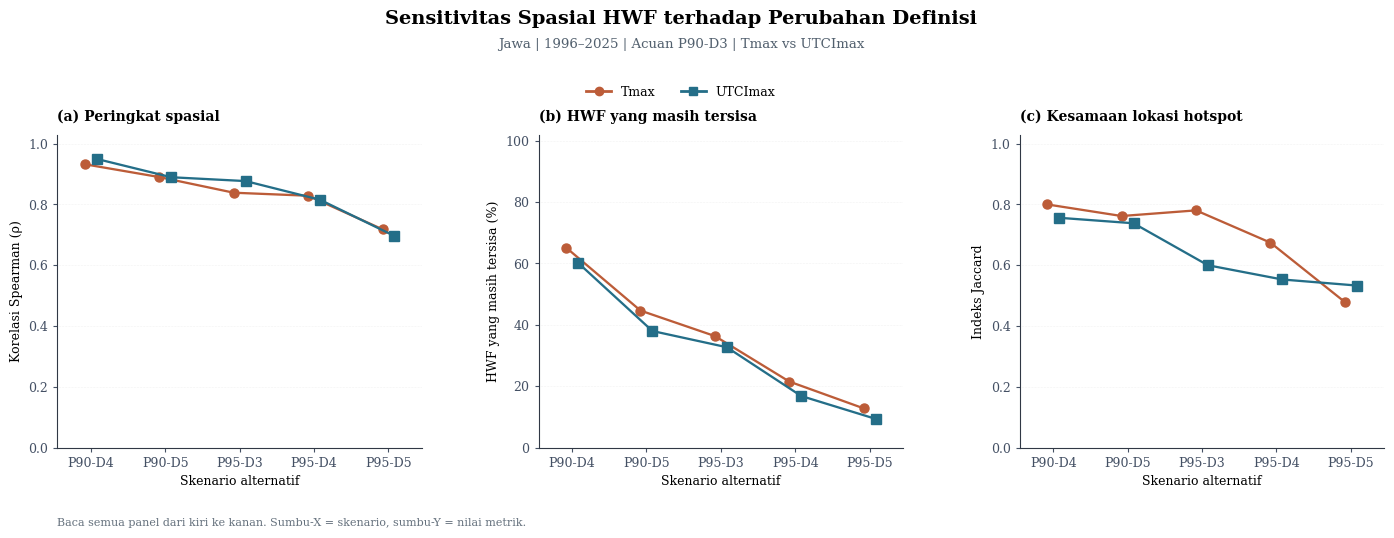

WindowsPath('D:/Daps/Data/UTCI/Hasil_UTCI_Jawa_1996_2025/TMAX_vs_UTCI_SENSITIVITAS_JAWA_P90D3_1996_2025/figures/FIG01_MAIN_Comparison_Spearman_HWF_Jaccard.png')

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14.5, 5.8), facecolor='white')
fig.subplots_adjust(left=.07, right=.985, bottom=.22, top=.76, wspace=.32)

scenario_labels = [s.replace('_', '-') for s in OTHER_SCENARIOS]
x = np.arange(len(OTHER_SCENARIOS), dtype=float)
metrics = [
    ('spearman_rho', 'Korelasi Spearman (ρ)', (0, 1.03), '(a) Peringkat spasial'),
    ('hwf_remaining_percent', 'HWF yang masih tersisa (%)', (0, 102), '(b) HWF yang masih tersisa'),
    ('hotspot_jaccard', 'Indeks Jaccard', (0, 1.03), '(c) Kesamaan lokasi hotspot')
]
offsets = {'Tmax': -0.08, 'UTCImax': 0.08}
markers = {'Tmax': 'o', 'UTCImax': 's'}

for ax, (metric, ylabel, ylim, title) in zip(axes, metrics):
    for ind in ['Tmax', 'UTCImax']:
        df = (summary_df.query('indicator == @ind')
              .set_index('scenario')
              .reindex(OTHER_SCENARIOS))

        if metric == 'hwf_remaining_percent':
            vals = 100.0 - df['reduction_regional_percent'].to_numpy(dtype=float)
        else:
            vals = df[metric].to_numpy(dtype=float)

        ax.plot(x + offsets[ind], vals,
                marker=markers[ind], markersize=6.5, lw=1.65,
                color=PALETTE[ind], label=ind)

    ax.set_xticks(x, scenario_labels)
    ax.set_xlim(-0.45, len(x) - 0.55)
    ax.set_ylim(*ylim)
    ax.set_title(title, loc='left', weight='bold', fontsize=10, pad=10)
    ax.set_xlabel('Skenario alternatif', fontsize=9)
    ax.set_ylabel(ylabel, fontsize=9)
    ax.grid(axis='y', ls=':', alpha=.3)
    ax.spines[['top', 'right']].set_visible(False)

fig.suptitle('Sensitivitas Spasial HWF terhadap Perubahan Definisi',
             y=.975, fontsize=14, weight='bold')
fig.text(.5, .91, 'Jawa | 1996–2025 | Acuan P90-D3 | Tmax vs UTCImax',
         ha='center', fontsize=9.6, color='#52606e')
handles = [Line2D([0], [0], marker='o', lw=2, color=PALETTE['Tmax'], label='Tmax'),
           Line2D([0], [0], marker='s', lw=2, color=PALETTE['UTCImax'], label='UTCImax')]
fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(.5, .864),
           ncol=2, frameon=False)
fig.text(.07, .085,
         'Baca semua panel dari kiri ke kanan. Sumbu-X = skenario, sumbu-Y = nilai metrik.',
         fontsize=8, color='#65717d')
save_figure(fig, 'FIG01_MAIN_Comparison_Spearman_HWF_Jaccard')



## FIGURE 01A — Grafik Spearman SAJA (paling mudah dibaca)
**Inilah grafik Spearman yang kamu tanyakan.** Sumbu X = korelasi Spearman ρ antara **HWF spasial P90-D3** dan **HWF skenario** pada grid yang sama. Sumbu Y = lima definisi alternatif. Titik oranye = Tmax dan biru = UTCImax. Nilai ρ ditulis langsung di ujung titik.

Semakin mendekati **+1**, semakin mirip urutan wilayah dengan HWF tinggi/rendah dibanding benchmark. Korelasi tinggi **tidak berarti jumlah hari heatwave tetap sama**.

✓ D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\TMAX_vs_UTCI_SENSITIVITAS_JAWA_P90D3_1996_2025\figures\FIG01A_MAIN_Spearman_Spatial_HWF_Tmax_UTCImax.png


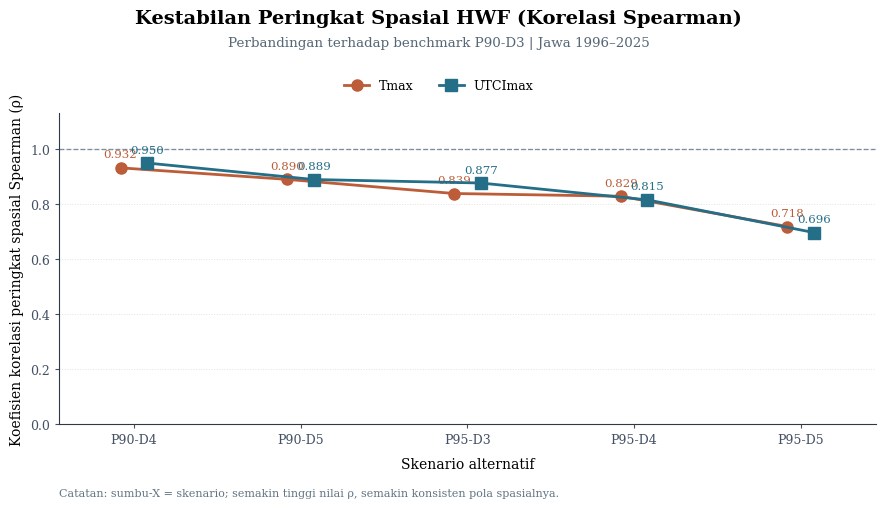

WindowsPath('D:/Daps/Data/UTCI/Hasil_UTCI_Jawa_1996_2025/TMAX_vs_UTCI_SENSITIVITAS_JAWA_P90D3_1996_2025/figures/FIG01A_MAIN_Spearman_Spatial_HWF_Tmax_UTCImax.png')

In [9]:
# FIGURE 01A — DOT PLOT KHUSUS SPEARMAN, dengan sumbu-X = skenario
fig, ax = plt.subplots(figsize=(9.5, 5.35), facecolor='white')
fig.subplots_adjust(left=.10, right=.96, top=.78, bottom=.20)

scenario_labels = [s.replace('_', '-') for s in OTHER_SCENARIOS]
x = np.arange(len(OTHER_SCENARIOS), dtype=float)
offsets = {'Tmax': -0.08, 'UTCImax': 0.08}
markers = {'Tmax': 'o', 'UTCImax': 's'}

for ind in ['Tmax', 'UTCImax']:
    tab = (summary_df[summary_df.indicator == ind]
           .set_index('scenario')
           .reindex(OTHER_SCENARIOS))
    vals = tab['spearman_rho'].to_numpy(dtype=float)

    ax.plot(x + offsets[ind], vals,
            marker=markers[ind], ms=8, lw=2,
            color=PALETTE[ind], label=ind, zorder=4)

    for xx, value in zip(x + offsets[ind], vals):
        if np.isfinite(value):
            ax.text(xx, value + 0.03, f'{value:.3f}',
                    fontsize=8.5, ha='center', va='bottom', color=PALETTE[ind])

ax.set_xticks(x, scenario_labels)
ax.set_xlim(-0.45, len(x) - 0.55)
ax.set_ylim(0, 1.13)
ax.axhline(1, lw=.95, color='#778899', ls='--', zorder=1)
ax.set_xlabel('Skenario alternatif', fontsize=10, labelpad=8)
ax.set_ylabel('Koefisien korelasi peringkat spasial Spearman (ρ)', fontsize=10)
ax.grid(axis='y', ls=':', lw=.7, alpha=.35)
ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Kestabilan Peringkat Spasial HWF (Korelasi Spearman)', fontsize=14,
             weight='bold', y=.975)
fig.text(.5, .905, 'Perbandingan terhadap benchmark P90-D3 | Jawa 1996–2025',
         ha='center', fontsize=9.7, color='#566776')
fig.legend(loc='upper center', bbox_to_anchor=(.5, .865), ncol=2, frameon=False, fontsize=9)
fig.text(.10, .065, 'Catatan: sumbu-X = skenario; semakin tinggi nilai ρ, semakin konsisten pola spasialnya.',
         fontsize=8, color='#627582')
save_figure(fig, 'FIG01A_MAIN_Spearman_Spatial_HWF_Tmax_UTCImax')



## Gambar Utama 2 — P90-D3 dibanding P95-D5 secara spasial (PALING MUDAH DIJELASKAN)
**Disarankan masuk Bab III** sebagai contoh perubahan spasial paling besar. Baris = Tmax dan UTCImax. Kolom = HWF P90-D3, HWF P95-D5, dan **penurunan absolut** dari benchmark (hari/tahun). Skala warna P90-D3 dan P95-D5 dibuat sama untuk dua indikator; skala penurunan juga sama.

✓ D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\TMAX_vs_UTCI_SENSITIVITAS_JAWA_P90D3_1996_2025\figures\FIG02_MAIN_Benchmark_vs_P95D5_Tmax_UTCImax.png


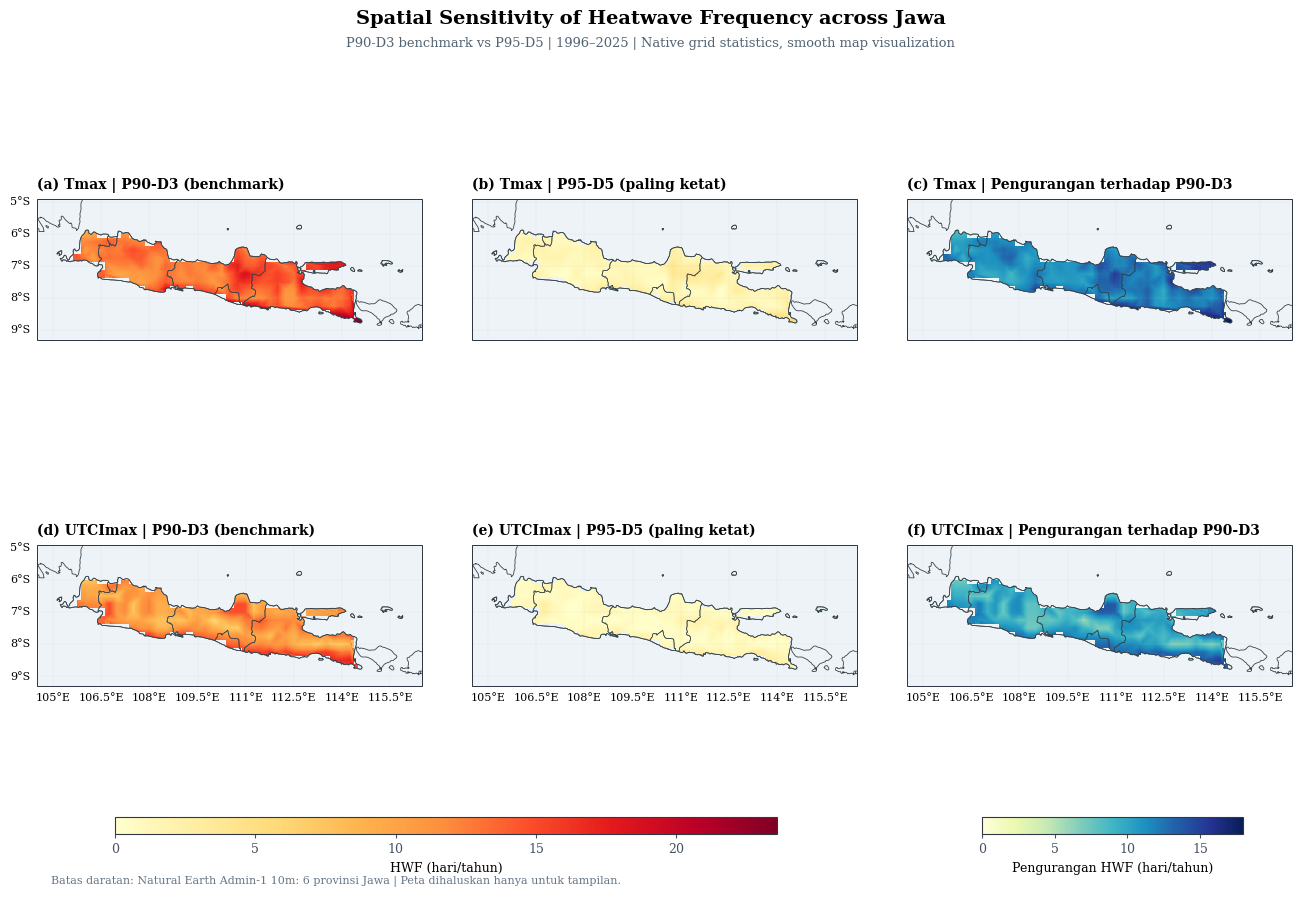

WindowsPath('D:/Daps/Data/UTCI/Hasil_UTCI_Jawa_1996_2025/TMAX_vs_UTCI_SENSITIVITAS_JAWA_P90D3_1996_2025/figures/FIG02_MAIN_Benchmark_vs_P95D5_Tmax_UTCImax.png')

In [10]:
# FIGURE 02 — PETA SMOOTH SEPERTI NOTEBOOK SPASIAL AWAL (2x3)
strict='P95_D5'
valid_hwf=np.hstack([statistics[i][s]['hwf'][np.isfinite(statistics[i][s]['hwf'])]
                     for i in ['Tmax','UTCImax'] for s in [BENCHMARK,strict]])
valid_loss=np.hstack([(-statistics[i][strict]['delta'])[np.isfinite(statistics[i][strict]['delta'])]
                      for i in ['Tmax','UTCImax']])
hwf_norm=Normalize(vmin=0,vmax=max(1,float(np.max(valid_hwf))))
loss_norm=Normalize(vmin=0,vmax=max(1,float(np.max(valid_loss))))
fig=plt.figure(figsize=(14.1,9.3),facecolor='white')
gs=fig.add_gridspec(2,3,left=.065,right=.955,bottom=.17,top=.85,wspace=.13,hspace=.21)
for row,ind in enumerate(['Tmax','UTCImax']):
    fieldlist=[statistics[ind][BENCHMARK]['hwf'],statistics[ind][strict]['hwf'],
               -statistics[ind][strict]['delta']]
    titles=['P90-D3 (benchmark)','P95-D5 (paling ketat)','Pengurangan terhadap P90-D3']
    for col,(field,ttl) in enumerate(zip(fieldlist,titles)):
        ax=make_map_axis(fig,gs[row,col])
        draw_continuous(ax,ind,field,'YlOrRd' if col<2 else 'YlGnBu',
                        hwf_norm if col<2 else loss_norm)
        decorate_map(ax,f'({chr(97+row*3+col)}) {ind} | {ttl}',
                     left=col==0,bottom=row==1)
fig.suptitle('Spatial Sensitivity of Heatwave Frequency across Jawa',
             fontsize=14,weight='bold',y=.975)
fig.text(.5,.935,'P90-D3 benchmark vs P95-D5 | 1996–2025 | Native grid statistics, smooth map visualization',
         ha='center',fontsize=9.4,color='#526372')
cb1=fig.add_axes([.12,.089,.47,.018]);cb2=fig.add_axes([.735,.089,.185,.018])
fig.colorbar(ScalarMappable(cmap='YlOrRd',norm=hwf_norm),cax=cb1,
             orientation='horizontal').set_label('HWF (hari/tahun)',fontsize=9)
fig.colorbar(ScalarMappable(cmap='YlGnBu',norm=loss_norm),cax=cb2,
             orientation='horizontal').set_label('Pengurangan HWF (hari/tahun)',fontsize=9)
fig.text(.075,.035,f'Batas daratan: {GEOMETRY_SOURCE} | Peta dihaluskan hanya untuk tampilan.',
         fontsize=8,color='#667684')
save_figure(fig,'FIG02_MAIN_Benchmark_vs_P95D5_Tmax_UTCImax')


## Gambar pendukung — peta penurunan persentase terhadap P90-D3
Peta **lima skenario** ini memperlihatkan perubahan HWF per grid. Panel keenam berisi penjelasan. Skala warna tetap 0–100% untuk setiap provinsi dan skenario. **Nilai 0 pada denominator tidak diubah jadi 0%**: grid tanpa HWF pada benchmark tetap dikosongkan.


✓ D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\TMAX_vs_UTCI_SENSITIVITAS_JAWA_P90D3_1996_2025\figures\FIG03_SUPPORT_Spatial_Percent_Reduction_Tmax.png


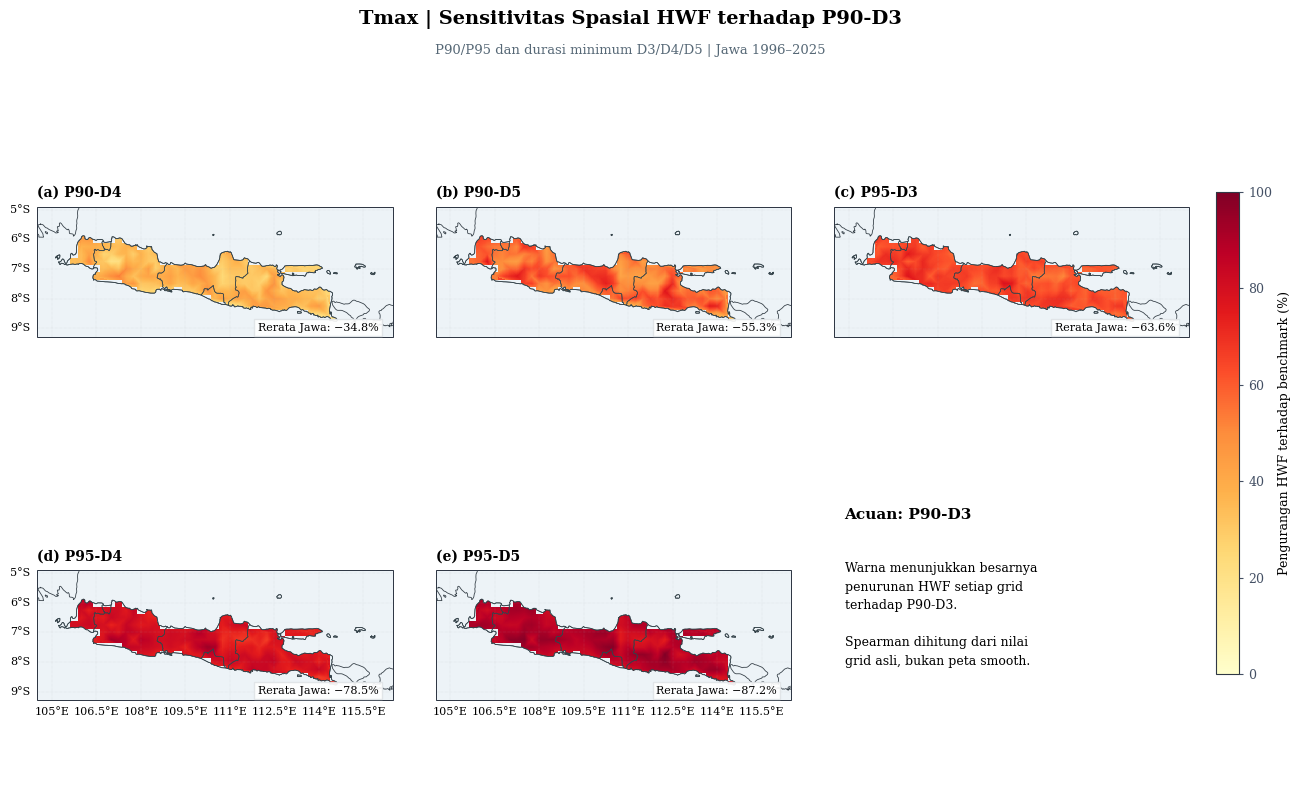

✓ D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\TMAX_vs_UTCI_SENSITIVITAS_JAWA_P90D3_1996_2025\figures\FIG03_SUPPORT_Spatial_Percent_Reduction_UTCImax.png


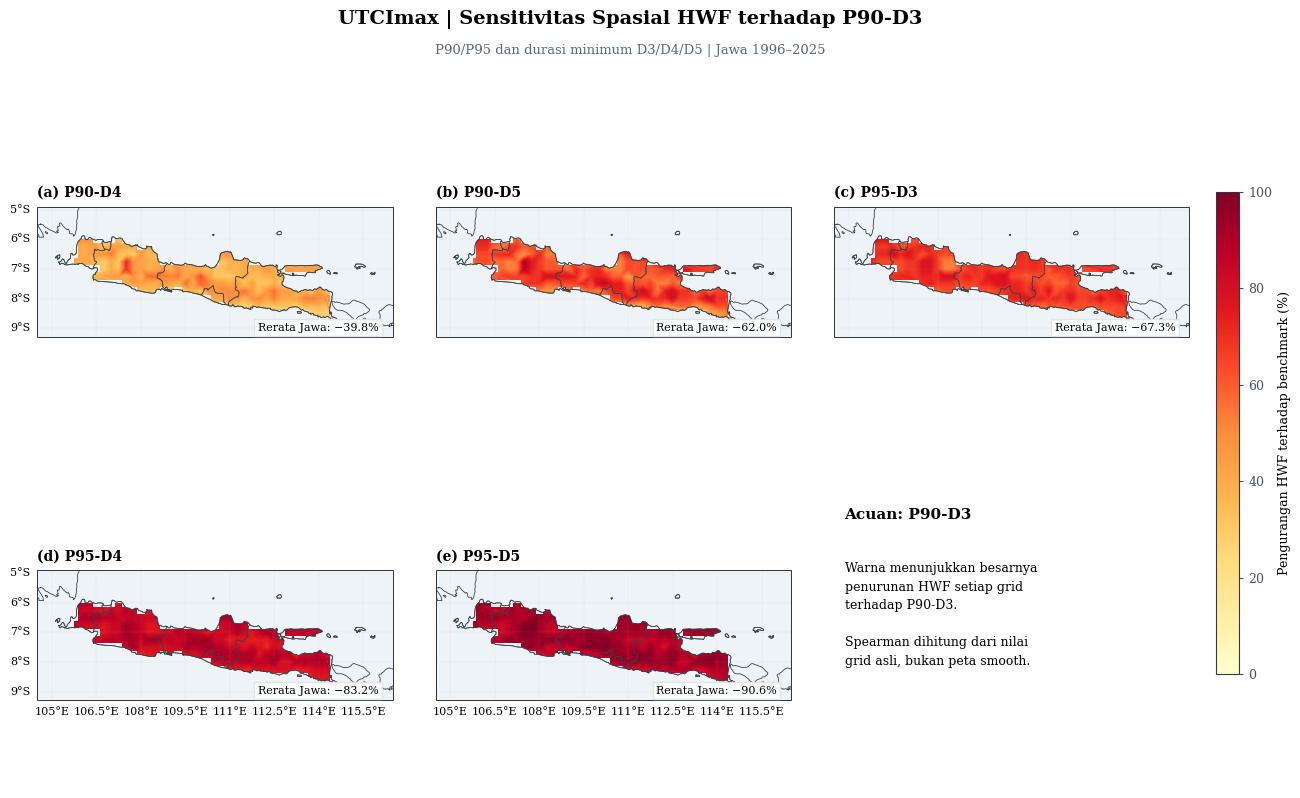

In [11]:
# FIGURES 03–04 — 5 SKENARIO, PETA SMOOTH + BATAS PROVINSI
for ind in ['Tmax','UTCImax']:
    fig=plt.figure(figsize=(13.8,9.1),facecolor='white')
    gs=fig.add_gridspec(2,3,left=.07,right=.905,bottom=.12,top=.855,
                        wspace=.12,hspace=.19)
    for i,sc in enumerate(OTHER_SCENARIOS):
        row,col=divmod(i,3)
        ax=make_map_axis(fig,gs[row,col])
        draw_continuous(ax,ind,statistics[ind][sc]['reduction'],'YlOrRd',Normalize(0,100))
        reg=float(summary_df.loc[(summary_df.indicator==ind)&(summary_df.scenario==sc),
                                  'reduction_regional_percent'].iloc[0])
        decorate_map(ax,f'({chr(97+i)}) {sc.replace("_","-")}',left=col==0,bottom=row==1)
        ax.text(.96,.035,f'Rerata Jawa: −{reg:.1f}%',transform=ax.transAxes,
                fontsize=8,ha='right',va='bottom',zorder=9,
                bbox=dict(facecolor='white',alpha=.92,edgecolor='#e0e4e7',pad=2.5))
    ax_note=fig.add_subplot(gs[1,2]);ax_note.axis('off')
    ax_note.text(.03,.88,'Acuan: P90-D3',fontsize=11,weight='bold',transform=ax_note.transAxes)
    ax_note.text(.03,.74,'Warna menunjukkan besarnya\npenurunan HWF setiap grid\nterhadap P90-D3.\n\n'
                  'Spearman dihitung dari nilai\ngrid asli, bukan peta smooth.',
                  fontsize=9,linespacing=1.55,va='top',transform=ax_note.transAxes)
    fig.suptitle(f'{ind} | Sensitivitas Spasial HWF terhadap P90-D3',fontsize=14,weight='bold',y=.975)
    fig.text(.50,.927,'P90/P95 dan durasi minimum D3/D4/D5 | Jawa 1996–2025',
             fontsize=9.5,ha='center',color='#566876')
    cb=fig.add_axes([.924,.245,.017,.53])
    fig.colorbar(ScalarMappable(cmap='YlOrRd',norm=Normalize(0,100)),cax=cb).set_label(
        'Pengurangan HWF terhadap benchmark (%)',fontsize=9)
    save_figure(fig,f'FIG03_SUPPORT_Spatial_Percent_Reduction_{ind}')


## Gambar opsional — kategori hotspot (native, tanpa smoothing)
Hotspot merupakan **kategori diskret** yang tidak boleh diinterpolasi secara linear. Warna kategori ditampilkan pada grid asli; batas provinsi tetap mengikuti SHP. Jaccard menunjukkan persentase kesamaan relatif lokasi hotspot, bukan nilai intensitas panas.


✓ D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\TMAX_vs_UTCI_SENSITIVITAS_JAWA_P90D3_1996_2025\figures\FIG05_OPTIONAL_P95D5_Hotspot_Persistence.png


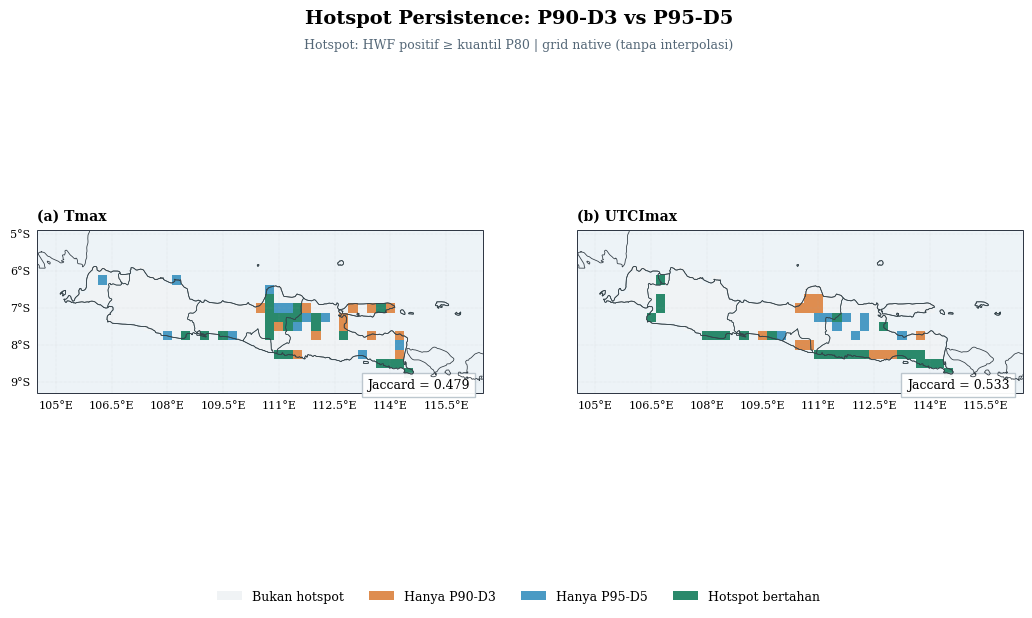

In [12]:
# FIGURE 05 — HOTSPOT KATEGORIK PADA GRID NATIVE (TIDAK DIHALUSKAN)
if MAKE_OPTIONAL_HOTSPOT_FIGURE:
    hotspot_colors=['#f0f3f5','#de8d50','#4a9ac4','#2a896b']
    hotspot_cmap=ListedColormap(hotspot_colors)
    hotspot_norm=BoundaryNorm([-.5,.5,1.5,2.5,3.5],4)
    fig=plt.figure(figsize=(11.2,6.8),facecolor='white')
    gs=fig.add_gridspec(1,2,left=.07,right=.95,bottom=.22,top=.81,wspace=.21)
    for i,ind in enumerate(['Tmax','UTCImax']):
        ax=make_map_axis(fig,gs[i])
        col=collections[ind]
        z=statistics[ind]['P95_D5']['hotspot_class'].astype(float).copy()
        z[z<0]=np.nan
        kw={'cmap':hotspot_cmap,'norm':hotspot_norm,'rasterized':True,'zorder':2}
        if HAS_CARTOPY:kw['transform']=ccrs.PlateCarree()
        ax.pcolormesh(col['lon'],col['lat'],np.ma.masked_invalid(z),shading='nearest',**kw)
        decorate_map(ax,f'({chr(97+i)}) {ind}',left=i==0,bottom=True)
        j=float(summary_df.loc[(summary_df.indicator==ind)&(summary_df.scenario=='P95_D5'),
                               'hotspot_jaccard'].iloc[0])
        ax.text(.97,.03,f'Jaccard = {j:.3f}',transform=ax.transAxes,
                fontsize=9,ha='right',bbox=dict(facecolor='white',alpha=.95,edgecolor='#b9c4cc'))
    fig.suptitle('Hotspot Persistence: P90-D3 vs P95-D5',fontsize=14,weight='bold',y=.96)
    fig.text(.5,.903,'Hotspot: HWF positif ≥ kuantil P80 | grid native (tanpa interpolasi)',
             fontsize=9,ha='center',color='#546777')
    labels=['Bukan hotspot','Hanya P90-D3','Hanya P95-D5','Hotspot bertahan']
    handles=[mpatches.Patch(facecolor=hotspot_colors[i],label=labels[i]) for i in range(4)]
    fig.legend(handles=handles,loc='lower center',bbox_to_anchor=(.5,.07),ncol=4,frameon=False)
    save_figure(fig,'FIG05_OPTIONAL_P95D5_Hotspot_Persistence')


## FIGURE 06 — Scatter Spearman pada grid asli (pelengkap pembuktian)
Dua panel dengan sumbu X = HWF P90-D3 dan Y = HWF P95-D5 (hari/tahun). **Setiap titik adalah satu grid Jawa**, bukan satu provinsi atau satu tahun. Annotasi Spearman ρ dihitung dari grid native yang sama.


✓ D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\TMAX_vs_UTCI_SENSITIVITAS_JAWA_P90D3_1996_2025\figures\FIG06_SUPPORT_Scatter_Spearman_P90D3_vs_P95D5.png


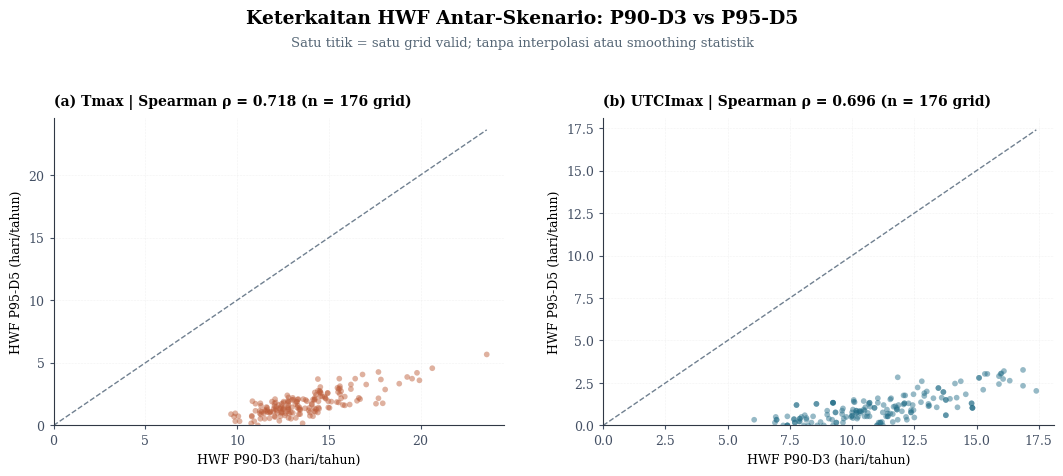

WindowsPath('D:/Daps/Data/UTCI/Hasil_UTCI_Jawa_1996_2025/TMAX_vs_UTCI_SENSITIVITAS_JAWA_P90D3_1996_2025/figures/FIG06_SUPPORT_Scatter_Spearman_P90D3_vs_P95D5.png')

In [13]:
# FIGURE 06 — NATIVE-GRID SCATTER P90-D3 vs P95-D5; SPEARMAN ρ
fig,axarr=plt.subplots(1,2,figsize=(11.3,5.3),facecolor='white')
fig.subplots_adjust(left=.085,right=.97,top=.77,bottom=.19,wspace=.22)
for k,ind in enumerate(['Tmax','UTCImax']):
    ax=axarr[k]
    col=collections[ind]
    ref=statistics[ind][BENCHMARK]['hwf']; alt=statistics[ind]['P95_D5']['hwf']
    valid=col['valid'] & np.isfinite(ref) & np.isfinite(alt)
    x,y=ref[valid],alt[valid]
    rho=safe_correlations(ref,alt,valid)[0]
    ax.scatter(x,y,s=17,alpha=.48,color=PALETTE[ind],edgecolor='none',rasterized=True)
    mx=max(1.,float(np.max(x)),float(np.max(y)))
    ax.plot([0,mx],[0,mx],ls='--',color='#708090',lw=1,label='1:1 reference')
    ax.set_xlim(0,mx*1.04);ax.set_ylim(0,mx*1.04)
    ax.set_xlabel('HWF P90-D3 (hari/tahun)',fontsize=9)
    ax.set_ylabel('HWF P95-D5 (hari/tahun)',fontsize=9)
    ax.set_title(f'({chr(97+k)}) {ind} | Spearman ρ = {rho:.3f} (n = {len(x)} grid)',
                 loc='left',weight='bold',fontsize=10,pad=9)
    ax.grid(ls=':',alpha=.3)
    ax.spines[['top','right']].set_visible(False)
fig.suptitle('Keterkaitan HWF Antar-Skenario: P90-D3 vs P95-D5',
             fontsize=13.5,weight='bold',y=.975)
fig.text(.5,.905,'Satu titik = satu grid valid; tanpa interpolasi atau smoothing statistik',
         ha='center',fontsize=9.5,color='#566776')
save_figure(fig,'FIG06_SUPPORT_Scatter_Spearman_P90D3_vs_P95D5')


## 4 — Ekspor semua tabel dan peta numerik (bukan hasil interpolasi)
Semua nilai mentah klimatologi HWF, penurunan absolut, penurunan persen, dan kategori hotspot disimpan dalam NetCDF terpisah untuk Tmax dan UTCImax; tabel juga disimpan CSV dan Excel. Angka pada gambar bukan diketik manual: semuanya diperoleh dari `summary_df` setelah proses *load* dan QC.

In [14]:
summary_file=TABLE_DIR/'TABEL_LENGKAP_SpatialSensitivity_HWF_P90D3_1996_2025.csv'
summary_df.to_csv(summary_file,index=False,float_format='%.6f')
for ind,col in collections.items():
    st=statistics[ind]
    ds=xr.Dataset(
        data_vars={
            'HWF':(('scenario','latitude','longitude'),np.stack([st[s]['hwf'] for s in SCENARIOS]).astype('float32')),
            'HWF_delta_scenario_minus_benchmark':(('scenario','latitude','longitude'),np.stack([st[s]['delta'] for s in SCENARIOS]).astype('float32')),
            'HWF_reduction_percent':(('scenario','latitude','longitude'),np.stack([st[s]['reduction'] for s in SCENARIOS]).astype('float32')),
            'hotspot_class':(('scenario','latitude','longitude'),np.stack([st[s]['hotspot_class'] for s in SCENARIOS]).astype('int16'))},
        coords={'scenario':SCENARIOS,'latitude':col['lat'],'longitude':col['lon']},
        attrs={'indicator':ind,'baseline':BENCHMARK,'period':'1996-2025',
               'weights':'cos(latitude)', 'hotspot_top_fraction':HOTSPOT_TOP_FRACTION,
               'geospatial_interpolation':'NONE; numeric data native grid'})
    ds['HWF'].attrs['units']='days/year'
    ds['HWF_delta_scenario_minus_benchmark'].attrs['units']='days/year'
    ds['HWF_reduction_percent'].attrs['units']='percent'
    outfile=MAP_DIR/f'{ind}_Sensitivity_NATIVE_1996_2025.nc'
    ds.to_netcdf(outfile)
    ds.close()
    print('✓ NetCDF:',outfile)
meta={'period':'1996-2025','baseline':BENCHMARK,'scenarios':SCENARIOS,
      'hotspot_fraction':HOTSPOT_TOP_FRACTION,'weights':'cos(latitude)',
      'smoothed_maps_only':EFFECTIVE_RENDER=='smooth',
      'Spearman':'descriptive spatial ranks; no spatial-autocorrelation-adjusted p-values',
      'HWF_metric_source':'original Tmax .npz and UTCI .nc annual metric caches'}
(OUTPUT_DIR/'metadata_FINAL.json').write_text(json.dumps(meta,indent=2,ensure_ascii=False),encoding='utf-8')
print('\nTabel utama:',TABLE_DIR/'TABEL_UTAMA_SENSITIVITAS_P90D3.csv')
print('Tabel lengkap:',summary_file)
print('Semua gambar:',PLOT_DIR)

✓ NetCDF: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\TMAX_vs_UTCI_SENSITIVITAS_JAWA_P90D3_1996_2025\maps_netcdf\Tmax_Sensitivity_NATIVE_1996_2025.nc
✓ NetCDF: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\TMAX_vs_UTCI_SENSITIVITAS_JAWA_P90D3_1996_2025\maps_netcdf\UTCImax_Sensitivity_NATIVE_1996_2025.nc

Tabel utama: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\TMAX_vs_UTCI_SENSITIVITAS_JAWA_P90D3_1996_2025\tables\TABEL_UTAMA_SENSITIVITAS_P90D3.csv
Tabel lengkap: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\TMAX_vs_UTCI_SENSITIVITAS_JAWA_P90D3_1996_2025\tables\TABEL_LENGKAP_SpatialSensitivity_HWF_P90D3_1996_2025.csv
Semua gambar: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\TMAX_vs_UTCI_SENSITIVITAS_JAWA_P90D3_1996_2025\figures


## Panduan pemilihan gambar untuk Bab III

**Masukkan ke hasil utama:** `FIG01A_MAIN` (grafik Spearman yang jelas), `FIG01_MAIN` (komparasi Spearman–penurunan HWF–Jaccard), dan `FIG02_MAIN` (peta smooth P90-D3 vs P95-D5).

**Pendukung/lampiran:** `FIG03_SUPPORT` masing-masing indikator (lima skenario penurunan HWF), `FIG05_OPTIONAL` kategori hotspot (native, tidak di-smooth), dan `FIG06_SUPPORT` scatter Spearman terhadap benchmark.

**Penting:** P90-D3 adalah *benchmark internal*. Spearman tinggi = peringkat HWF antargrid relatif konsisten; HWF tetap bisa menurun besar. Penyimpulan signifikansi korelasi spasial memerlukan mempertimbangkan autokorelasi grid; plot ini bersifat deskriptif.
